In [1]:
import torch.nn as nn
import torchvision
import torch
from torchinfo import summary
from DWT import DWT_2D
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd
import ast
from scipy import stats
from tqdm import tqdm
import time

import os
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import roc_auc_score, confusion_matrix, accuracy_score, precision_recall_fscore_support
import seaborn as sns

from IXCM import IXCNet
from Loss import bce_loss, var_loss

In [2]:
class TB11KDataset(Dataset):
    def __init__(self, list_path, img_root_path, transform=None):
        """
        Args:
            list_path: txt索引文件路径 (e.g., ./TB11K/lists/TBX11K_train.txt)
            img_root_path: 图片根目录 (e.g., ./TB11K/img)
            transform: 图片预处理
        """
        self.img_root_path = img_root_path
        self.transform = transform
        self.img_paths = []
        self.labels = []

        with open(list_path, 'r') as f:
            lines = f.readlines()
            for line in lines:
                # 假设txt格式为: "folder/filename.png label" 或 纯路径
                # 这里我们只取第一部分的路径字符串
                parts = line.strip().split()
                rel_path = parts[0]
                
                # 路径修正：TB11K txt中有时包含 'imgs/' 前缀，需根据实际情况调整
                # 你的描述是图片在 ./TB11K/img/health 等，所以我们拼接路径
                full_path = os.path.join(self.img_root_path, rel_path)
                
                # 标签逻辑: health/sick -> 0 (Non-TB), tb -> 1 (TB)
                # 检查路径字符串中是否包含目录名
                # 注意：根据你的描述，sick是患病非结核，health是健康，都算0
                # tb是结核，算1
                # 路径通常包含 'health', 'sick', 'tb' 字符串
                if '/tb/' in rel_path or rel_path.startswith('tb/'):
                    label = 1.0
                else:
                    label = 0.0
                
                self.img_paths.append(full_path)
                self.labels.append(label)

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        label = self.labels[idx]

        # 打开图片并转为灰度 (你的DenseNet修改了conv0接受1通道)
        try:
            image = Image.open(img_path).convert('L') 
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")
            # 返回一个黑图防止崩溃，或者你可以选择跳过
            image = Image.new('L', (256, 256))

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor([label], dtype=torch.float32)

In [3]:
def train_one_epoch(model, dataloader, criterion_bce, criterion_var, optimizer, device, gc=0.01, loss_mode='bcevar', var_weight=1.0, img_dec=True):
    model.train()
    
    # 累加器
    run_loss = 0.0
    run_bce = 0.0
    run_var = 0.0
    
    preds_list = []
    labels_list = []

    for inputs, labels in dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # Forward
        alphas, betas, outs = model(inputs)

        # Loss 计算
        loss_bce = criterion_bce(outs, labels)

        # 解析 alpha/beta (ydim=1)
        # alpha_s = alphas[:, 0:1]
        # alpha_a = alphas[:, 1:2]
        # beta_s  = betas[:, 0:1]
        # beta_a  = betas[:, 1:2]
            
        if loss_mode == 'bcevar':
            if img_dec:
                alpha_s = alphas[:, 0::2]  
                beta_s  = betas[:, 0::2]
                alpha_a = alphas[:, 1::2]
                beta_a  = betas[:, 1::2]
                loss_var = criterion_var(alpha_s, beta_s, alpha_a, beta_a, labels)
            else:
                alpha_s = alphas
                beta_s  = betas
                loss_var = criterion_var(alpha_s, beta_s, alpha_s, beta_s, labels)
            loss = loss_bce + var_weight * loss_var
        else:
            loss = loss_bce

        loss.backward()
        # 1. 计算当前的梯度总范数 (在裁剪前)
        #total_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1e6) # 这里设个无穷大只是为了算值，不裁剪
        
        # [调试打印] 看看平时是多少，爆炸时是多少
        # 建议只在每个 epoch 的前几个 batch 打印，防止刷屏
        #print(f"Gradient Norm: {total_norm:.4f}")
        # 梯度裁剪，防止BCE损失和VAR损失对抗带来的梯度陡增
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=gc)
        optimizer.step()

        # 记录数值 (batch_size 加权)
        bs = inputs.size(0)
        run_loss += loss.item() * bs
        run_bce  += loss_bce.item() * bs
        if loss_mode == 'bcevar':
            run_var  += loss_var.item() * bs
            
        
        # 收集预测结果用于计算指标
        preds_list.extend(outs.detach().cpu().numpy())
        labels_list.extend(labels.cpu().numpy())

    # 计算 Epoch 平均值
    dataset_size = len(dataloader.dataset)
    epoch_loss = run_loss / dataset_size
    epoch_bce  = run_bce / dataset_size
    epoch_var  = run_var / dataset_size
    
    # 计算指标
    preds_arr = np.array(preds_list)
    labels_arr = np.array(labels_list)
    preds_bin = preds_arr > 0.5
    
    # acc = accuracy_score(labels_arr, preds_bin)
    correct_prediction = (preds_bin == labels_arr)
    class_accs = np.mean(correct_prediction, axis=0)
    acc = np.mean(class_accs)
    # 防止只有一个类别导致AUC报错
    try:
        auc = roc_auc_score(labels_arr, preds_arr, average='macro')
    except ValueError:
        auc = 0.5 

    return epoch_loss, epoch_bce, epoch_var, acc, auc

def validate(model, dataloader, criterion_bce, criterion_var, device, loss_mode='bcevar', var_weight=1.0, img_dec=True):
    model.eval()
    
    # 累加器
    run_loss = 0.0
    run_bce = 0.0
    run_var = 0.0
    
    preds_list = []
    labels_list = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            alphas, betas, outs = model(inputs)

            loss_bce = criterion_bce(outs, labels)
            
            if loss_mode=='bcevar':
                if img_dec:
                    alpha_s = alphas[:, 0::2]  
                    beta_s  = betas[:, 0::2]
                    alpha_a = alphas[:, 1::2]
                    beta_a  = betas[:, 1::2]
                    loss_var = criterion_var(alpha_s, beta_s, alpha_a, beta_a, labels)
                else:
                    alpha_s = alphas
                    beta_s  = betas
                    loss_var = criterion_var(alpha_s, beta_s, alpha_s, beta_s, labels)
                loss = loss_bce + var_weight * loss_var
            else:
                loss = loss_bce

            bs = inputs.size(0)
            run_loss += loss.item() * bs
            run_bce  += loss_bce.item() * bs
            if loss_mode == 'bcevar':
                run_var  += loss_var.item() * bs

            preds_list.extend(outs.cpu().numpy())
            labels_list.extend(labels.cpu().numpy())

    dataset_size = len(dataloader.dataset)
    epoch_loss = run_loss / dataset_size
    epoch_bce  = run_bce / dataset_size
    epoch_var  = run_var / dataset_size
    
    preds_arr = np.array(preds_list)
    labels_arr = np.array(labels_list)
    preds_bin = preds_arr > 0.5
    
    # acc = accuracy_score(labels_arr, preds_bin)
    correct_prediction = (preds_bin == labels_arr)
    class_accs = np.mean(correct_prediction, axis=0)
    acc = np.mean(class_accs)
    try:
        auc = roc_auc_score(labels_arr, preds_arr, average='macro')
    except ValueError:
        auc = 0.5

    return epoch_loss, epoch_bce, epoch_var, acc, auc, labels_arr, preds_bin

In [4]:
class EarlyStopping:
    """
    当验证集损失在 patience 个 epoch 内没有改善时停止训练。
    """
    def __init__(self, patience=7, verbose=False, delta=0, path='checkpoint.pth', trace_func=print):
        """
        Args:
            patience (int): 上次验证集损失改善后等待的 epoch 数。
            verbose (bool): 如果为 True，则打印每一步的日志。
            delta (float): 只有变化量超过 delta 才被认为是改善。
            path (str): 保存最佳模型权重的路径。
            trace_func (function): 用于打印日志的函数。
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf
        self.delta = delta
        self.path = path
        self.trace_func = trace_func

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                self.trace_func(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        '''验证集损失减少时保存模型'''
        if self.verbose:
            self.trace_func(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}).  Saving model ...')
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss

# ==========================================
# 2. 高级训练策略函数
# ==========================================
def train_model_with_strategy(
    model, 
    train_loader, 
    val_loader, 
    criterion_bce, 
    criterion_var, 
    device,
    epochs=50,
    lr_start=1e-3, 
    lr_end=1e-6,
    warmup_epochs=5,  # 预热轮数
    use_early_stopping=True,
    patience=10,
    use_scheduler=True,
    weight_decay=0.01,
    gradient_clip=3.0,
    loss_mode='bcevar',
    var_weight=1.0,
    save_dir='./checkpoints',
    img_dec=True
):
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)

    best_acc = 0.0
    best_auc = 0.0
    best_loss = 1e8
    best_bce = 1e8
    best_var = 1e8
    # 1. 定义优化器 (初始设为 lr_start, 但前几个epoch会被覆盖)
    optimizer = optim.Adam(model.parameters(), lr=lr_start, weight_decay=weight_decay)
    
    # 2. 定义调度器
    # 注意: T_max 应该是剩余的 "正式训练" 轮数
    scheduler = None
    if use_scheduler:
        scheduler_epochs = epochs - warmup_epochs
        if scheduler_epochs > 0:
            scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=scheduler_epochs, eta_min=lr_end)
    
    early_stopping = EarlyStopping(patience=patience, verbose=False, path='best_model_strategy.pth')

    history = {
        'train': {'loss': [], 'bce': [], 'var': [], 'acc': [], 'auc': []},
        'val':   {'loss': [], 'bce': [], 'var': [], 'acc': [], 'auc': []},
        'lr': []
    }

    print(f"{'='*100}")
    print(f"Start Training: Total Epochs={epochs}")
    if use_scheduler:
        print(f"Strategy: Warmup ({warmup_epochs} epochs @ {lr_end:.1e}) -> CosineAnnealing ({lr_start:.1e}->{lr_end:.1e})")
    else:
        print(f"Strategy: Constant Learning Rate ({lr_start:.1e})")
    print(f"{'='*100}")
    for epoch in range(epochs):
        epoch_start_time = time.time()
        if use_scheduler:
            # --- 分支 A: 开启调度 (预热 + 退火) ---
            if epoch < warmup_epochs:
                # 预热阶段：强制使用最小学习率
                current_lr = lr_end
                for param_group in optimizer.param_groups:
                    param_group['lr'] = current_lr
                phase_name = "Warmup"
            else:
                # 正式阶段：
                # 如果是预热结束后的第一个epoch，先确保LR重置回lr_start，让Scheduler接管
                if epoch == warmup_epochs:
                    for param_group in optimizer.param_groups:
                        param_group['lr'] = lr_start
                
                current_lr = optimizer.param_groups[0]['lr']
                phase_name = "Anneal"
        else:
            # --- 分支 B: 关闭调度 (恒定学习率) ---
            # 保持优化器初始化时的 lr_start 不变
            # 也可以在这里强制赋值以防万一，但通常不需要
            current_lr = optimizer.param_groups[0]['lr'] 
            phase_name = "Constant"

        # --- 训练 ---
        t_loss, t_bce, t_var, t_acc, t_auc = train_one_epoch(
            model, train_loader, criterion_bce, criterion_var, optimizer, device, gc=gradient_clip, loss_mode=loss_mode, var_weight=var_weight, img_dec=img_dec
        )
        
        # --- 验证 ---
        v_loss, v_bce, v_var, v_acc, v_auc, _, _ = validate(
            model, val_loader, criterion_bce, criterion_var, device, loss_mode=loss_mode, var_weight=var_weight, img_dec=img_dec
        )
        
        # --- 调度器更新逻辑 ---
        if use_scheduler and scheduler is not None and epoch >= warmup_epochs:
            scheduler.step()
            
        epoch_end_time = time.time()
        epoch_duration = epoch_end_time - epoch_start_time
        epoch_mins = int(epoch_duration // 60)
        epoch_secs = int(epoch_duration % 60)

        # --- 记录 ---
        history['train']['loss'].append(t_loss)
        history['train']['bce'].append(t_bce)
        history['train']['var'].append(t_var)
        history['train']['acc'].append(t_acc)
        history['train']['auc'].append(t_auc)
        
        history['val']['loss'].append(v_loss)
        history['val']['bce'].append(v_bce)
        history['val']['var'].append(v_var)
        history['val']['acc'].append(v_acc)
        history['val']['auc'].append(v_auc)
        history['lr'].append(current_lr)

        # --- 格式化打印 (增加阶段标识) ---
        print(f"Epoch [{epoch+1:02d}/{epochs:02d}] [{phase_name}] LR: {current_lr:.2e} Time: {epoch_mins}m {epoch_secs}s")
        print(f"  Train | Loss: {t_loss:.4f} (BCE: {t_bce:.4f}, Var: {t_var:.4f}) | Acc: {t_acc:.4f} | AUC: {t_auc:.4f}")
        print(f"  Val   | Loss: {v_loss:.4f} (BCE: {v_bce:.4f}, Var: {v_var:.4f}) | Acc: {v_acc:.4f} | AUC: {v_auc:.4f}")

        if v_loss < best_loss:
            best_loss = v_loss
            save_path_loss = os.path.join(save_dir, 'best_model_loss.pth')
            torch.save(model.state_dict(), save_path_loss)
            print(f"  -> [Saved] Best Loss updated: {best_loss:.4f}")

        if v_bce < best_bce:
            best_bce = v_bce
            save_path_bce = os.path.join(save_dir, 'best_model_bce.pth')
            torch.save(model.state_dict(), save_path_bce)
            print(f"  -> [Saved] Best BCE updated: {best_bce:.4f}")

        if v_var < best_var:
            best_var = v_var
            save_path_var = os.path.join(save_dir, 'best_model_var.pth')
            torch.save(model.state_dict(), save_path_var)
            print(f"  -> [Saved] Best VAR updated: {best_var:.4f}")
            
        if v_acc > best_acc:
            best_acc = v_acc
            save_path_acc = os.path.join(save_dir, 'best_model_acc.pth')
            torch.save(model.state_dict(), save_path_acc)
            print(f"  -> [Saved] Best Acc updated: {best_acc:.4f}")
        
        if v_auc > best_auc:
            best_auc = v_auc
            save_path_auc = os.path.join(save_dir, 'best_model_auc.pth')
            torch.save(model.state_dict(), save_path_auc)
            print(f"  -> [Saved] Best AUC updated: {best_auc:.4f}")
            
        print("-" * 100)

        # --- 早停 ---
        if use_early_stopping:
            early_stopping(v_loss, model)
            if early_stopping.early_stop:
                print(f"Early stopping triggered at epoch {epoch+1}!")
                break
    
    if use_early_stopping:
        print("Loading best model weights...")
        model.load_state_dict(torch.load('best_model_strategy.pth'))

    return model, history

In [5]:
def plot_loss_curve(train_losses, val_losses, save_path='./loss_curve.png', metric_name='Loss') :
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label=f'Train {metric_name}')
    plt.plot(val_losses, label=f'Val {metric_name}')
    plt.title(f'Training and Validation {metric_name}')
    plt.xlabel('Epochs')
    if metric_name == "AUC" or metric_name == "ACC":
        plt.ylim([0, 1.1])
    plt.ylabel(f'{metric_name}')
    plt.legend()
    plt.grid(True)
    plt.savefig(save_path)
    plt.show()

In [6]:
def seed_everything(seed=42):
    """
    固定所有随机种子以保证实验可复现性
    """
    # 1. Python标准库
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # 2. NumPy
    np.random.seed(seed)
    
    # 3. PyTorch
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # 如果使用多卡
    
    # 4. CuDNN (最关键的一步)
    # 保证卷积算法选择的确切性
    torch.backends.cudnn.deterministic = True 
    # 禁止寻找最优卷积算法（虽然会稍微降低速度，但能保证完全一致）
    torch.backends.cudnn.benchmark = False

    print(f"Random Seed set to: {seed}")

In [7]:
# --- 配置参数 ---
seed_everything(42) # 固定随机种子保证结果可复现
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 32
# 路径配置
IMG_ROOT = '/teams/Xray_1751630141/TB11K/imgs'
TRAIN_LIST = '/teams/Xray_1751630141/TB11K/TBX11K/lists/TBX11K_train.txt'
VAL_LIST = '/teams/Xray_1751630141/TB11K/TBX11K/lists/TBX11K_val.txt'
CheXNet_weights_path = "./CNNmodels/CheXNet/CheXNet.pth.tar"
# --- 数据准备 ---
# 你的DenseNet conv0改为了1通道，且 IXCNet 需要 DWT，建议尺寸保持 256 或 512
# DWT 通常要求输入尺寸是偶数
# 如果图像分解功能关闭 (img_dec=False) ，需要将resize的尺寸变为256,256 ，以保证消融实验的公平性。
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((512, 512)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ToTensor(),
        # 如果是灰度图，ToTensor后是 [1, H, W]，通常不需要 Normalize 或者用 0.5
        transforms.Normalize([0.5], [0.5]) 
    ]),
    'val': transforms.Compose([
        transforms.Resize((512, 512)),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])
    ]),
}

train_dataset = TB11KDataset(TRAIN_LIST, IMG_ROOT, transform=data_transforms['train'])
val_dataset = TB11KDataset(VAL_LIST, IMG_ROOT, transform=data_transforms['val'])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

print(f"Train samples: {len(train_dataset)}, Val samples: {len(val_dataset)}")

Random Seed set to: 42
Train samples: 6600, Val samples: 1800


/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/root/miniconda3/envs/myconda/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Start Training: Total Epochs=200
Strategy: Warmup (0 epochs @ 1.0e-05) -> CosineAnnealing (1.0e-04->1.0e-05)
Epoch [01/200] [Anneal] LR: 1.00e-04 Time: 2m 27s
  Train | Loss: 0.7756 (BCE: 0.3031, Var: 0.4725) | Acc: 0.9417 | AUC: 0.7531
  Val   | Loss: 0.5659 (BCE: 0.2785, Var: 0.2874) | Acc: 0.9339 | AUC: 0.8667
  -> [Saved] Best Loss updated: 0.5659
  -> [Saved] Best BCE updated: 0.2785
  -> [Saved] Best VAR updated: 0.2874
  -> [Saved] Best Acc updated: 0.9339
  -> [Saved] Best AUC updated: 0.8667
----------------------------------------------------------------------------------------------------
Epoch [02/200] [Anneal] LR: 1.00e-04 Time: 1m 18s
  Train | Loss: 0.4623 (BCE: 0.2495, Var: 0.2128) | Acc: 0.9517 | AUC: 0.8167
  Val   | Loss: 0.5424 (BCE: 0.2640, Var: 0.2785) | Acc: 0.9372 | AUC: 0.8922
  -> [Saved] Best Loss updated: 0.5424
  -> [Saved] Best BCE updated: 0.2640
  -> [Saved] Best VAR updated: 0.2785
  -> [Saved] Best Acc updated: 0.9372
  -> [Saved] Best AUC updated: 0.8

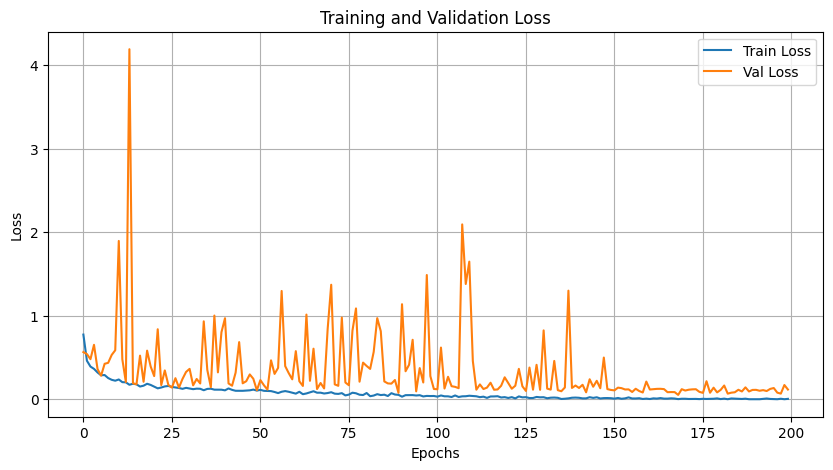

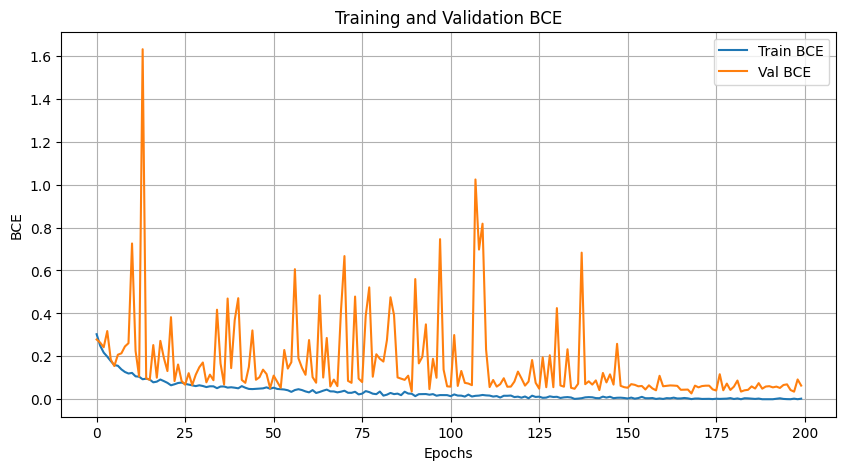

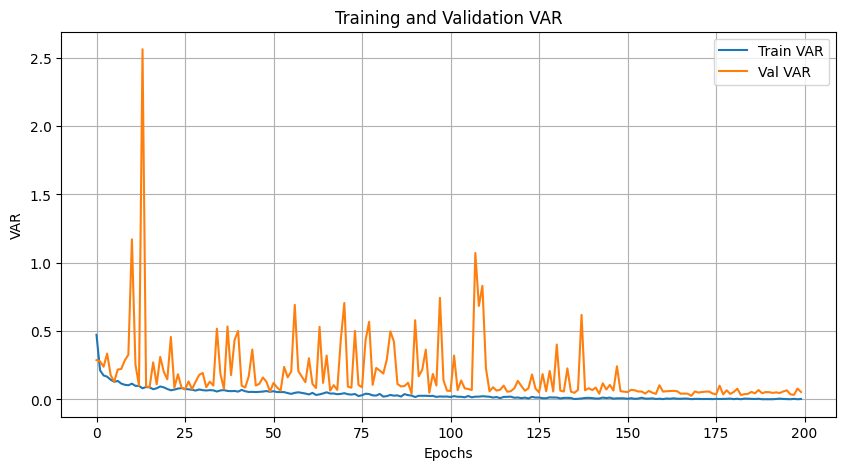

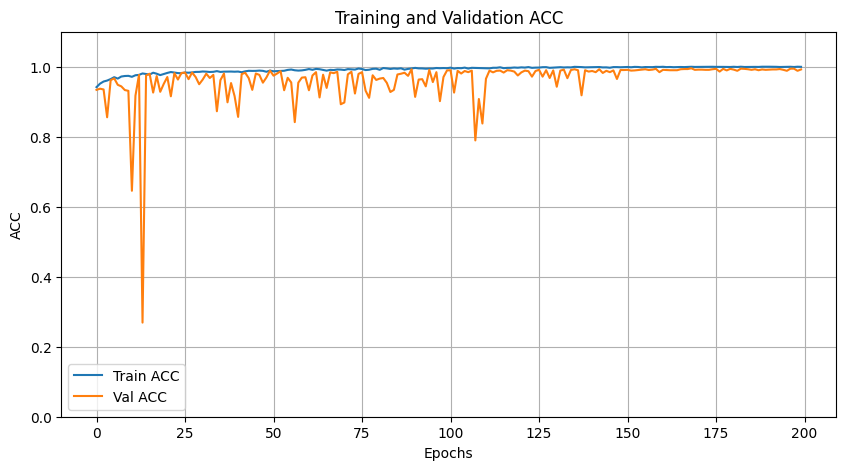

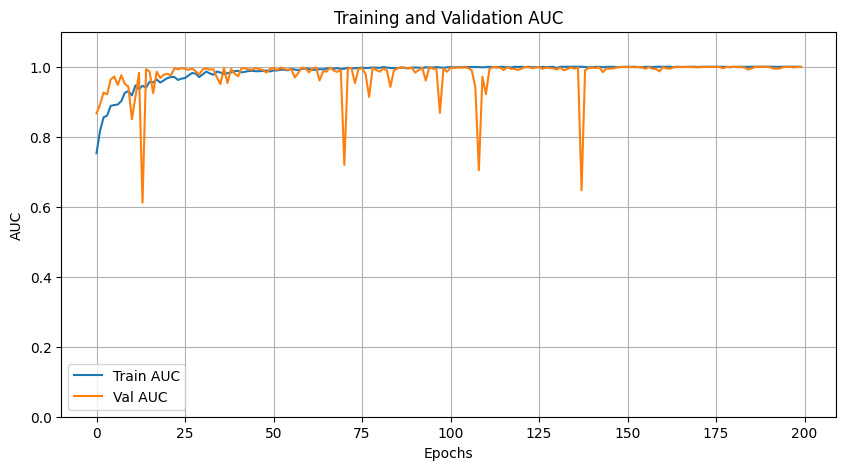

In [8]:
backbone_list = ['vit', 'resnet50']
for backbone in backbone_list:
    # 配置你的高级参数
    result_root_path = './result/TB11K/0211'
    weight_decay = 0.0001
    gradient_clip = 1.0
    var_weight = 1.0
    KL_lmd = 0.1
    loss_mode = 'bcevar'
    lr=0.0001
    img_dec=False
    result_root_path = result_root_path + f'_{backbone}'+ '_wd' + str(weight_decay).replace('.', '_') + '_gc' + str(gradient_clip).replace('.', '_') + '_vw' + str(var_weight).replace('.', '_') + '_lm_' + loss_mode + '_lr_' + str(lr)  + '_kllmd_' + str(KL_lmd) + '_imgdec_' + str(int(img_dec))
    STRATEGY_PARAMS = {
        'epochs': 200,           # 总 Epoch 设大一点，让早停去控制
        'lr_start': lr,       # 初始学习率 (刚开始大一点快速收敛)
        'lr_end': 1e-5,         # 结束学习率 (最后小一点精细微调)
        'use_early_stopping': False,
        'patience': 8,
        'warmup_epochs': 0,
        'use_scheduler': True,
        'weight_decay': weight_decay,
        'gradient_clip': gradient_clip,
        'loss_mode': loss_mode,
        'var_weight': var_weight,
        'save_dir': result_root_path,
        'img_dec': img_dec
    }

    # 重新实例化模型和损失函数（确保从头开始）
    model = IXCNet(backbone_name=backbone, evi_vec_dim=64, wavename='haar', ydim=1, img_dec=img_dec).to(DEVICE)
    # summary(model, input_size=(1, 1, 512, 512))
    # checkpoint = torch.load(CheXNet_weights_path)
    # model.shape_embed_layer.load_state_dict(checkpoint['state_dict'], strict=False) # 原模型为3通道输入
    criterion_bce = bce_loss(reduction='mean')
    criterion_var = var_loss(reduction='mean', lmd=KL_lmd, img_dec=img_dec)
    
    # 调用策略训练函数
    final_model, history = train_model_with_strategy(
        model, 
        train_loader, 
        val_loader, 
        criterion_bce, 
        criterion_var, 
        DEVICE,
        **STRATEGY_PARAMS
    )
    
    history_path = os.path.join(result_root_path, 'history.npy')
    np.save(history_path, history)
    
    # 画 Loss 曲线
    plot_loss_curve(history['train']['loss'], history['val']['loss'], save_path=result_root_path + '/loss_history.png', metric_name="Loss")
    plot_loss_curve(history['train']['bce'], history['val']['bce'], save_path=result_root_path + '/bce_history.png', metric_name="BCE")
    plot_loss_curve(history['train']['var'], history['val']['var'], save_path=result_root_path + '/var_history.png', metric_name="VAR")
    plot_loss_curve(history['train']['acc'], history['val']['acc'], save_path=result_root_path + '/acc_history.png', metric_name="ACC")
    plot_loss_curve(history['train']['auc'], history['val']['auc'], save_path=result_root_path + '/auc_history.png', metric_name="AUC")